# Лабораторная работа № 4
## Бинарная классификация
**Цель работы**: познакомиться с применением модели машинного обучения для решения задачи классификации (метод логической регрессии)

Проанализируем датасет salary. Датасет содержит информацию о рабочих разных профессий и информацию об их работе.

**Признаки**: 
* age – возраст 
* workclass – класс работы 
* fnlwgt –  колонка, которая показывает сколько людей с такими же характеристиками существует
* education – образование 
* education-num – номер образования
* marital-status – семейное положение 
* occupation – вид деятельности 
* relationship – степень родства 
* race – раса 
* sex – пол 
* capital-gain – прирост капитала 
* capital-loss – убыток капитала 
* hours-per-week – часов в неделю 
* native-country – страна происхождения 
* salary – зарплата

### 0. Импорт необходимых библиотек и загрузка датасета

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display
import seaborn as sns
%matplotlib inline
pd.set_option('display.max_columns', None)
data = pd.read_csv('salary.csv', skipinitialspace=True)
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### 1. Извлечём последнюю строку датафрейма

In [2]:
index = len(data) - 1
row_to_remove = data.iloc[index]
data = data.drop(index)
print("Удалённая строка (Series):")
print(row_to_remove)
print(f"Тип: {type(row_to_remove)}")

Удалённая строка (Series):
age                               52
workclass               Self-emp-inc
fnlwgt                        287927
education                    HS-grad
education-num                      9
marital-status    Married-civ-spouse
occupation           Exec-managerial
relationship                    Wife
race                           White
sex                           Female
capital-gain                   15024
capital-loss                       0
hours-per-week                    40
native-country         United-States
salary                          >50K
Name: 32560, dtype: object
Тип: <class 'pandas.core.series.Series'>


### 2. Проанализируем значения целевой переменной

Выведем целевую переменную, имена и частоту:

In [3]:
(unique, counts) = np.unique(data['salary'], return_counts=True)
print("Уникальные значения:", unique)
print("Кол-во:", counts)

Уникальные значения: ['<=50K' '>50K']
Кол-во: [24720  7840]


Построим столбчатую диаграмму

<Axes: xlabel='salary', ylabel='count'>

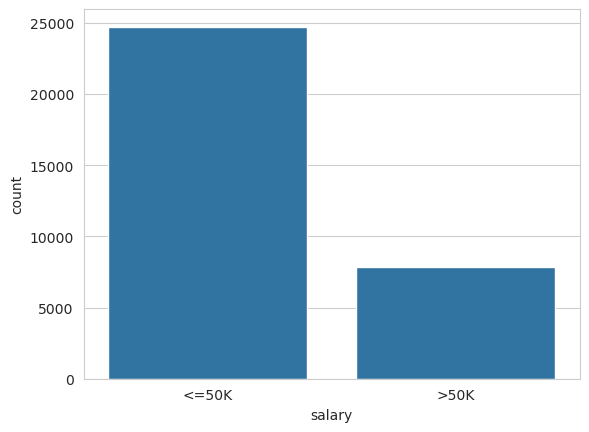

In [4]:
sns.set_style("whitegrid")
sns.countplot(data, x="salary")

Анализ показывает, что набор данных является несбалансированным ('>50K' < 30%)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32560 entries, 0 to 32559
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32560 non-null  int64 
 1   workclass       32560 non-null  object
 2   fnlwgt          32560 non-null  int64 
 3   education       32560 non-null  object
 4   education-num   32560 non-null  int64 
 5   marital-status  32560 non-null  object
 6   occupation      32560 non-null  object
 7   relationship    32560 non-null  object
 8   race            32560 non-null  object
 9   sex             32560 non-null  object
 10  capital-gain    32560 non-null  int64 
 11  capital-loss    32560 non-null  int64 
 12  hours-per-week  32560 non-null  int64 
 13  native-country  32560 non-null  object
 14  salary          32560 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


В наборе есть два класса: <=30K и >30K, задача бинарной классификации

### 3. Проверка на наличие пропущенных значений и выбросов

In [6]:
data.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
salary            0
dtype: int64

<Axes: xlabel='age'>

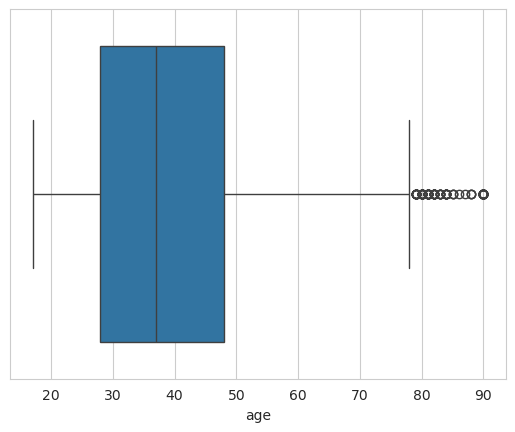

In [7]:
sns.boxplot(x=data['age'])

### 4. Исключаем невлияющие категориальные признаки

In [8]:
data_copy = data.copy()
# Принял решение убрать education, т.к. есть дублирующий числовой признак education-num
# Relationship, т.к. коррелирует с marital-status
# Race, т.к. не должен влиять на доход с этической точки зрения
# Native-country, т.к. подавляющее число значений - United States
cat_feat = ['education', 'relationship' ,'race', 'native-country']
data_copy.drop(cat_feat, axis=1, inplace=True)
data_copy.head()

,age,workclass,fnlwgt,education-num,marital-status,occupation,sex,capital-gain,capital-loss,hours-per-week,salary
0,39,State-gov,77516,13,Never-married,Adm-clerical,Male,2174,0,40,<=50K
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,Male,0,0,13,<=50K
2,38,Private,215646,9,Divorced,Handlers-cleaners,Male,0,0,40,<=50K
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,Male,0,0,40,<=50K
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,Female,0,0,40,<=50K


### 5. Заполняем пропущенные значения

Пропущенных значений нет, как было видно в лабораторной работе 3 и из пункта 3, поэтому заполнять их не требуется

### 6. Кодируем категориальные признаки

Признаки sex и salary будут закодированы по способу mapping, т.к. они являются бинарными. Остальные - способом OneHot (можно было сделать через LabelEncoder, как на последних слайдах, но как я понял, это не лучшее решение, т.к. модель будет считать, что есть какая-то зависимость от конкретных чисел)

In [9]:
sex = {'Male': 0, 'Female': 1}
salary = {'<=50K': 0, '>50K': 1}
data_copy['sex'] = data_copy['sex'].map(sex)
data_copy['salary'] = data_copy['salary'].map(salary)
data_copy.head()

,age,workclass,fnlwgt,education-num,marital-status,occupation,sex,capital-gain,capital-loss,hours-per-week,salary
0,39,State-gov,77516,13,Never-married,Adm-clerical,0,2174,0,40,0
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,0,0,0,13,0
2,38,Private,215646,9,Divorced,Handlers-cleaners,0,0,0,40,0
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,0,0,0,40,0
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,1,0,0,40,0


In [10]:
cats = ['workclass', 'marital-status', 'occupation']
data_copy = pd.get_dummies(data_copy, columns=cats, drop_first=True, dtype=int)
data_copy.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,salary,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving
0,39,77516,13,0,2174,0,40,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,50,83311,13,0,0,0,13,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,38,215646,9,0,0,0,40,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,53,234721,7,0,0,0,40,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
4,28,338409,13,1,0,0,40,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


Можно убрать первые столбцы в получившихся OneHot эквивалентах workclass, marital-status и occupation

In [11]:
cats = ['workclass_Federal-gov', 'marital-status_Married-AF-spouse', 'occupation_Adm-clerical']
data_copy.drop(cats, axis=1, inplace=True)
data_copy.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,salary,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving
0,39,77516,13,0,2174,0,40,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,50,83311,13,0,0,0,13,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,38,215646,9,0,0,0,40,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,53,234721,7,0,0,0,40,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
4,28,338409,13,1,0,0,40,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


### 7. Разделяем на признаки и целевую переменную 

In [12]:
y = data_copy['salary']
x = data_copy.drop('salary', axis=1)

### 8. Разделяем данные на тренировочный и тестовые наборы

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

### 9. Нормализация для численной устойчивости

In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### 10. Обучение модели логической регрессии

In [15]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight='balanced') # т.к. несбалансирован
model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### 11. Делаем прогноз

In [16]:
y_pred = model.predict(x_test_scaled)

### 12. Рассчитываем показатели

In [17]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()
print('TN =', TN)
print('FP =', FP)
print('FN =', FN)
print('TP =', TP)

accuracy = (TP + TN) / (TN + FP + FN + TP)
print(f'Accuracy: {accuracy:0.2f}')

TN = 4941
FP = 1225
FN = 324
TP = 1650
Accuracy: 0.81


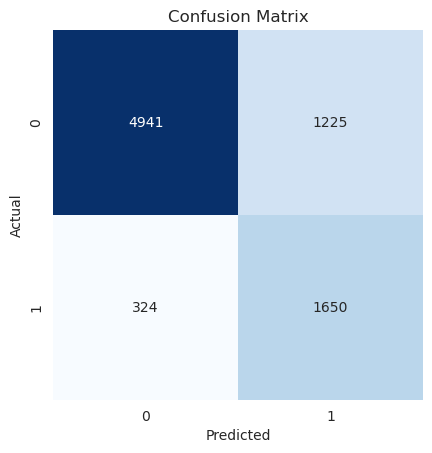

In [18]:
sns.heatmap(cm, square=True, annot=True, fmt='d', cbar=False, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [19]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy:{accuracy:0.2f}')

Accuracy:0.81


In [20]:
from sklearn.metrics import precision_score, recall_score
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print(f'Precision:{precision:0.2f}')
print(f'Recall:{recall:0.2f}')

Precision:0.57
Recall:0.84


In [21]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print(f'F1:{f1:0.2f}')

F1:0.68


In [22]:
data_copy.corr()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,salary,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving
age,1.000000,-0.076676,0.036541,-0.088879,0.077623,0.057782,0.068758,0.233998,0.060910,-0.019362,-0.198352,0.102578,0.136263,0.012770,0.013996,0.315656,0.016702,-0.534350,0.010216,0.265186,-0.010190,0.012527,0.099284,0.034216,-0.098574,-0.016250,-0.089337,0.015626,0.054183,0.003895,-0.031970,-0.019572,0.026917
fnlwgt,-0.076676,1.000000,-0.043183,-0.026900,0.000378,-0.010246,-0.018768,-0.009514,-0.002820,0.005031,0.042952,-0.024788,-0.039050,-0.010886,-0.003047,-0.026395,0.003637,0.037128,0.028472,-0.026241,0.004041,0.008476,-0.019276,-0.032927,0.029021,0.012769,-0.003710,0.007280,-0.016195,0.016571,0.003739,0.003770,0.001272
education-num,0.036541,-0.043183,1.000000,-0.012262,0.122662,0.079920,0.148123,0.335194,0.097938,-0.015117,-0.118508,0.077460,0.016463,0.102587,-0.008136,0.086094,-0.034224,-0.032119,-0.055154,-0.068047,0.000196,-0.143078,0.200979,-0.101535,-0.127937,-0.158507,-0.169689,-0.071639,0.419003,0.005775,0.030248,0.060701,-0.115963
sex,-0.088879,-0.026900,-0.012262,1.000000,-0.048566,-0.045559,-0.229315,-0.216075,0.037979,-0.001404,0.034768,-0.084286,-0.107442,0.019905,0.001162,-0.431874,0.038698,0.171471,0.109146,0.188500,-0.011690,-0.223119,-0.036850,-0.100093,-0.094020,-0.030492,0.153697,0.088705,0.028529,-0.064766,0.011520,0.016100,-0.132462
capital-gain,0.077623,0.000378,0.122662,-0.048566,1.000000,-0.031604,0.078415,0.223249,-0.006992,-0.002139,-0.038616,0.096624,0.031866,-0.010361,-0.001655,0.085816,-0.006536,-0.066298,-0.013223,-0.012156,-0.002425,-0.021979,0.060474,-0.011714,-0.023261,-0.025944,-0.040253,-0.007321,0.085249,-0.007128,0.011673,-0.009362,-0.018049
capital-loss,0.057782,-0.010246,0.079920,-0.045559,-0.031604,1.000000,0.054256,0.150546,0.014666,-0.003177,-0.027471,0.031763,0.021173,-0.002048,-0.004494,0.080475,-0.008356,-0.060628,-0.013063,-0.003363,0.005049,0.001091,0.048333,-0.010671,-0.021673,-0.016261,-0.040849,-0.011081,0.046253,-0.003175,0.009694,0.004828,-0.003283
hours-per-week,0.068758,-0.018768,0.148123,-0.229315,0.078415,0.054256,1.000000,0.229702,0.011576,-0.014262,-0.020930,0.127930,0.093884,-0.023201,-0.012973,0.212822,-0.007090,-0.197939,-0.016587,-0.107123,0.000309,0.057375,0.139226,0.094170,-0.042265,0.006598,-0.155873,-0.041467,0.060253,0.028102,0.009889,-0.013946,0.077596
salary,0.233998,-0.009514,0.335194,-0.216075,0.223249,0.150546,0.229702,1.000000,0.033107,-0.008258,-0.078452,0.139244,0.030036,0.014855,-0.011680,0.444667,-0.042527,-0.318420,-0.074380,-0.064375,-0.005043,-0.012556,0.214750,-0.051918,-0.087258,-0.069390,-0.156337,-0.037120,0.185896,0.028128,0.023709,0.025707,-0.021465
workclass_Local-gov,0.060910,-0.002820,0.097938,0.037979,-0.006992,0.014666,0.011576,0.033107,1.000000,-0.003843,-0.397574,-0.049355,-0.076256,-0.053407,-0.005436,0.015173,-0.005417,-0.041799,-0.002071,0.016145,-0.004358,-0.044353,-0.017921,-0.025401,-0.025615,-0.060832,-0.007809,-0.017771,0.164973,0.234996,-0.090352,-0.016295,0.007157
workclass_Never-worked,-0.019362,0.005031,-0.015117,-0.001404,-0.002139,-0.003177,-0.014262,-0.008258,-0.003843,1.000000,-0.022243,-0.002761,-0.004266,-0.002988,-0.000304,-0.009329,-0.001672,0.012061,-0.002644,-0.002601,-0.000244,-0.005565,-0.005539,-0.002602,-0.003073,-0.003753,-0.004920,-0.000994,-0.005597,-0.002091,-0.005210,-0.002512,-0.003330


### 13. Строим ROC-кривую

In [23]:
from sklearn.metrics import roc_curve, auc
y_score = model.predict_proba(x_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

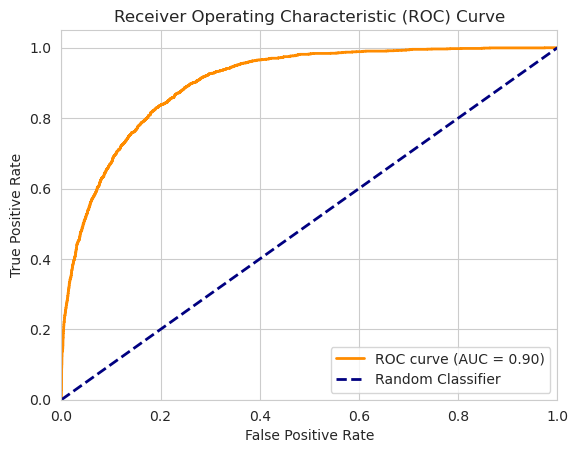

In [24]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### 14. Новые данные для прогноза 

In [25]:
new_data = pd.DataFrame({
    'age': [35],
    'fnlwgt': [150000],
    'education-num': [13],
    'sex': [0],
    'capital-gain': [0],
    'capital-loss': [0],
    'hours-per-week': [40],
    
    # workclass
    'workclass_Local-gov': [0],
    'workclass_Never-worked': [0],
    'workclass_Private': [1],  # Частный сектор
    'workclass_Self-emp-inc': [0],
    'workclass_Self-emp-not-inc': [0],
    'workclass_State-gov': [0],
    'workclass_Without-pay': [0],
    
    # marital-status
    'marital-status_Married-civ-spouse': [1],  # Женат/замужем
    'marital-status_Married-spouse-absent': [0],
    'marital-status_Never-married': [0],
    'marital-status_Separated': [0],
    'marital-status_Widowed': [0],
    
    # occupation
    'occupation_Armed-Forces': [0],
    'occupation_Craft-repair': [0],
    'occupation_Exec-managerial': [1],  # Руководитель
    'occupation_Farming-fishing': [0],
    'occupation_Handlers-cleaners': [0],
    'occupation_Machine-op-inspct': [0],
    'occupation_Other-service': [0],
    'occupation_Priv-house-serv': [0],
    'occupation_Prof-specialty': [0],
    'occupation_Protective-serv': [0],
    'occupation_Sales': [0],
    'occupation_Tech-support': [0],
    'occupation_Transport-moving': [0]
})

In [26]:
new_data_scaled = scaler.transform(new_data)

In [27]:
predicted_salary = model.predict(new_data_scaled)
print(f'Предсказанная зарплата: {'>50K' if predicted_salary[0] else '<=50K'}')

Предсказанная зарплата: >50K


In [28]:
predicted_proba = model.predict_proba(new_data_scaled)
print(f'Вероятности для классов [0, 1]: {predicted_proba[0]}')

Вероятности для классов [0, 1]: [0.14951219 0.85048781]


### 15. Исследовательский анализ данных

In [29]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

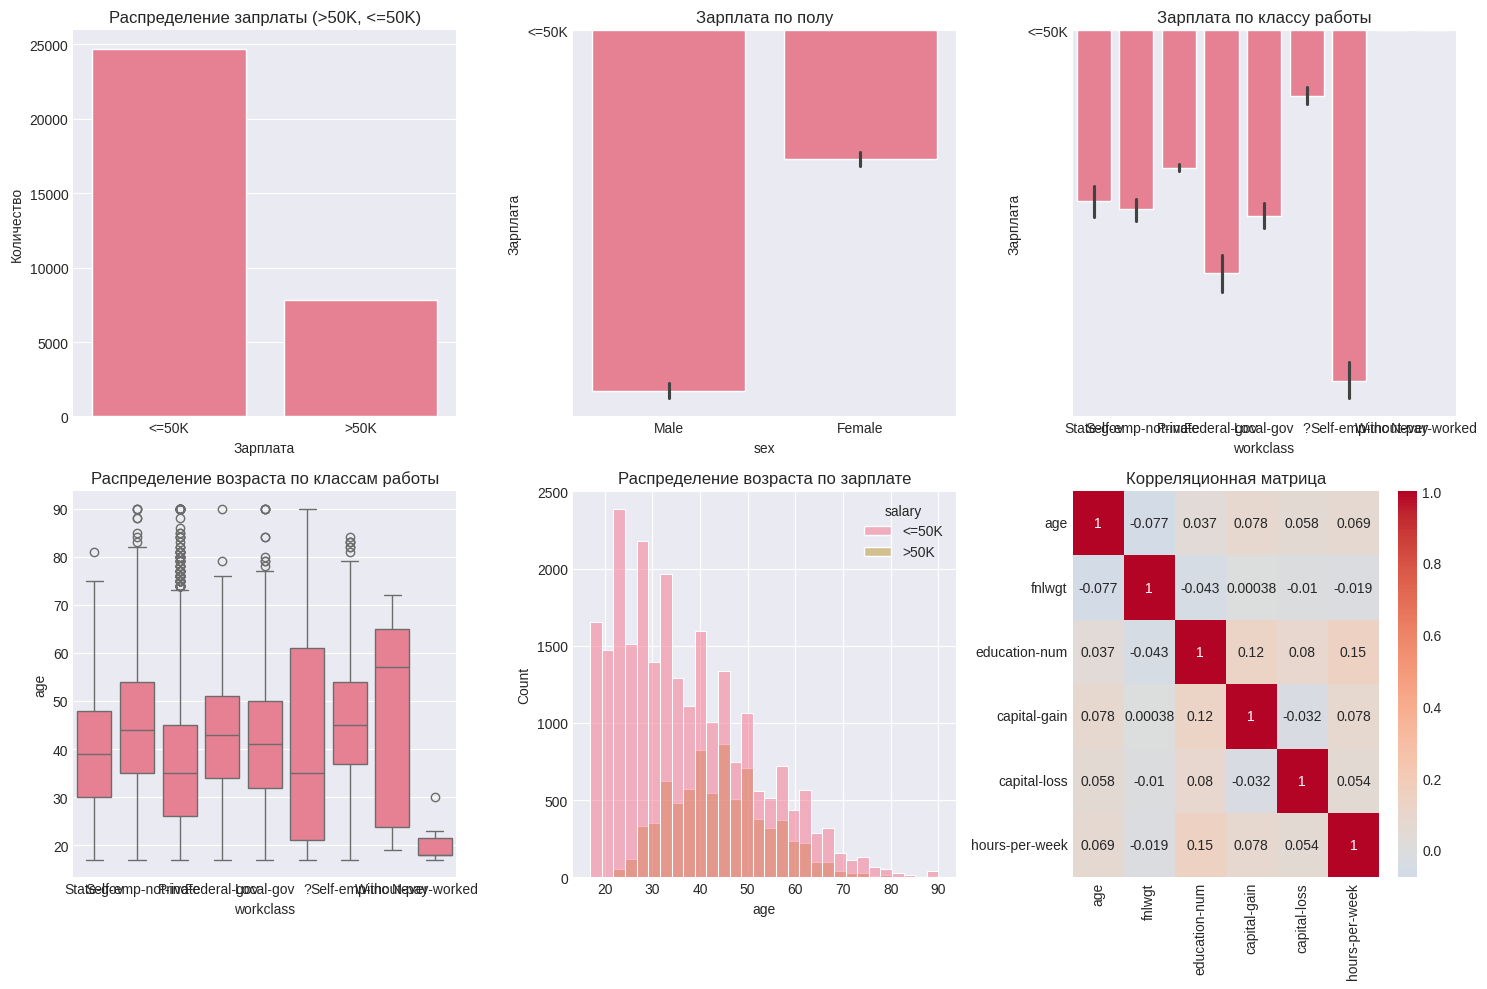

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

sns.countplot(data=data, x='salary', ax=axes[0, 0])
axes[0, 0].set_title('Распределение запрлаты (>50K, <=50K)')
axes[0, 0].set_xlabel('Зарплата')
axes[0, 0].set_ylabel('Количество')

sns.barplot(data=data, x='sex', y='salary', ax=axes[0, 1])
axes[0, 1].set_title('Зарплата по полу')
axes[0, 1].set_ylabel('Зарплата')

sns.barplot(data=data, x='workclass', y='salary', ax=axes[0, 2])
axes[0, 2].set_title('Зарплата по классу работы')
axes[0, 2].set_ylabel('Зарплата')

sns.boxplot(data=data, x='workclass', y='age', ax=axes[1, 0])
axes[1, 0].set_title('Распределение возраста по классам работы')

sns.histplot(data=data, x='age', hue='salary', bins=30, ax=axes[1, 1])
axes[1, 1].set_title('Распределение возраста по зарплате')

numeric_cols = data._get_numeric_data().columns.tolist()
corr_matrix = data[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=axes[1, 2])
axes[1, 2].set_title('Корреляционная матрица')

plt.tight_layout()
plt.show()